## Estimación del valor de $\pi$

Como ya se ha podido comentar antes, un algoritmo de tipo *Montecarlo* es un método probabilista acotado en tiempo de ejecución para encontrar la resolución de un problema.

A diferencias de los algoritmos tipo *Las Vegas*, estos algoritmos sacrifican una respuesta 100% exacta a costa del tiempo de ejecución. El tiempo esta acotado por *O(N)*, donde N es el tamaño de la entrada.

### Escenario

Consideremos un cuadrado de lado 2R, donde R corresponde al radio de un círculo unitario. Si se generan puntos al azar, el algoritmo identificará aquellos que queden inscritos dentro del círculo, donde el error considera a aquellos puntos generados pero que quedan fuera del circulo.

In [ ]:
# importaciones
import numpy as np
import time
import matplotlib.pyplot as plt

In [ ]:
# definición de la función tipo montecarlo
def estimar_pi(N:int, seed: int = 42) -> dict:
  np.random.seed(seed)
  t_inicio = time.perf_counter()

  # Generación de los puntos de manera aleatoria
  x = np.random.uniform(-1.0, 1.0, N)
  y = np.random.uniform(-1.0, 1.0, N)

  # Conteo de los puntos dentro del círculo
  distancia_cuadrada = x**2 + y**2
  dentro_del_circulo = distancia_cuadrada <= 1.0

  # Conteo y cálculo de la razón estocástica
  puntos_dentro = np.sum(dentro_del_circulo)
  pi_estimado = 4.0 * (puntos_dentro / N)

  t_fin = time.perf_counter()

  # Calculo del error
  error_absoluto = abs(pi_estimado - np.pi)
  error_relativo = (error_absoluto / np.pi) * 100.0

  return {
    "N" : N,
    "pi_estimado": pi_estimado,
    "error_absoluto": error_absoluto,
    "error_relativo": error_relativo,
    "tiempo_ejecucion": t_fin - t_inicio,
    "puntos_dentro": list(zip(x[dentro_del_circulo], y[dentro_del_circulo])),
    "puntos_fuera": list(zip(x[~dentro_del_circulo], y[~dentro_del_circulo])),
  }


In [ ]:
# Evaluación de la función
resultado = estimar_pi(10000)
print(f"N = { resultado['N'] }")
print(f"pi_estimado = { resultado['pi_estimado'] }")
print(f"error_absoluto = { resultado['error_absoluto'] } ")
print(f"error_relativo = { resultado['error_relativo'] } %")
print(f"tiempo_ejecucion = { resultado['tiempo_ejecucion'] } s")


N = 10000
pi_estimado = 3.1348
error_absoluto = 0.006792653589793307 
error_relativo = 0.21621687910530246 %
tiempo_ejecucion = 0.0012120010001126502 s


<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:4: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_2258/4047824836.py:4: SyntaxWarning: invalid escape sequence '\p'
  plt.title(f"Estimación de $\pi$ con {resultado['N']} puntos")


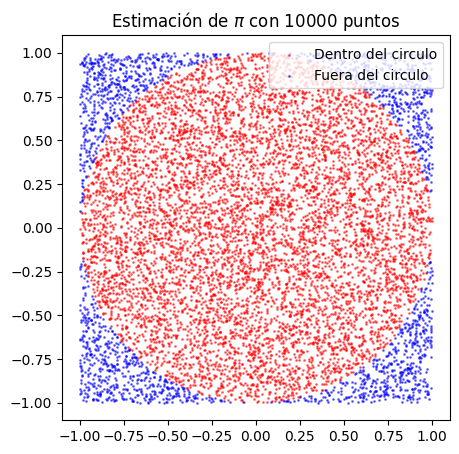

In [ ]:
fig = plt.figure(figsize=(5, 5))
plt.scatter(*zip(*resultado["puntos_dentro"]), s=1, alpha=0.5, color="red", label="Dentro del circulo")
plt.scatter(*zip(*resultado["puntos_fuera"]), s=1, alpha=0.5, color="blue", label="Fuera del circulo")
plt.title(f"Estimación de $\pi$ con {resultado['N']} puntos")
plt.xlim((-1.1, 1.1))
plt.ylim((-1.1, 1.1))
plt.legend()
plt.show()